In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,classification_report,ConfusionMatrixDisplay

In [5]:
cols=["buying","maint","doors","persons","lug_boot","safety","class"]
df=pd.read_csv("car_evaluation.csv",names=cols)
df.head(2)

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc


In [7]:
print(df['class'].value_counts())

class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


In [8]:
# Encode categorical columns
X = pd.get_dummies(df.drop("class", axis=1))
y = df["class"]


In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,random_state=42)

In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)

Accuracy: 0.9576107899807321
              precision    recall  f1-score   support

         acc       0.90      0.94      0.92       118
        good       0.71      0.79      0.75        19
       unacc       1.00      0.98      0.99       358
       vgood       0.86      0.79      0.83        24

    accuracy                           0.96       519
   macro avg       0.87      0.88      0.87       519
weighted avg       0.96      0.96      0.96       519



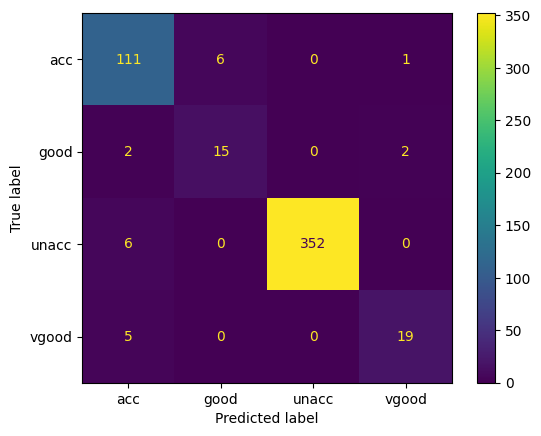

In [11]:
print("Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()


In [21]:
imp = pd.Series(rf.feature_importances_,
index=X.columns).sort_values(ascending=False)
print(imp.head(10))

safety_low      0.135683
persons_2       0.122928
safety_high     0.074439
safety_med      0.056511
persons_4       0.052254
buying_low      0.047258
maint_vhigh     0.046709
buying_vhigh    0.045593
persons_more    0.044952
buying_high     0.043469
dtype: float64
